# Auswertung instationärer Pumpversuche – Hantush-Verfahren

**Hydraulische Methoden · Hydrogeologie**

Dieses Notebook behandelt Pumpversuche in einem **halbgespannten (leaky) Grundwasserleiter** nach Hantush–Jacob. Die numerische Implementierung der Brunnenfunktion orientiert sich unter anderem an [T. N. Olsthoorn](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html).

**Lernziele:**

1. Theis- und Hantush-Typkurven vergleichen.
2. Einen synthetischen Pumpversuch simulieren und die Parameter **T** und **S** auswerten.
3. Bei unbekanntem Leakage-Parameter **r/B** die optimale Typkurve durch Parametersuche bestimmen.
4. Die Methode auf die Messwerte einer Übungsaufgabe anwenden.

**Benötigte Pakete:** `numpy`, `scipy`, `matplotlib`. Alle Berechnungen werden mit SI-Einheiten durchgeführt.

## 1. Theorie

### Was bedeutet halbgespannt?

Ein **halbgespannter Grundwasserleiter** (*semiconfined* bzw. *leaky aquifer*) wird von einer im Vergleich zum Aquifer **geringer durchlässigen**, aber nicht vollständig undurchlässigen Schicht (**Aquitarde**) überlagert oder unterlagert. Aufgrund von Potenzialunterschieden kann Wasser durch die Aquitarde vertikal zu- oder abströmen (*Leakage*). Bei einem Pumpversuch kann diese Nachlieferung die Absenkung gegenüber einem vollständig gespannten Grundwasserleiter verringern.

Als **typische Orientierung** wird für halbgespannte Verhältnisse eine um etwa **zwei bis vier Zehnerpotenzen geringere hydraulische Durchlässigkeit** der Aquitarde gegenüber dem Aquifer beschrieben (also näherungsweise **K/K′ = 10² bis 10⁴**; [Grundwasser.net: Halbgespannter Aquifer](https://www.grundwasser.net/pumpversuche/halbgespannter-aquifer-hantush)). Dies ist **keine allgemeingültige, scharfe Klassifikationsgrenze**. Für die hydraulische Wirkung sind insbesondere auch die Mächtigkeit der Aquitarde und damit ihr hydraulischer Widerstand entscheidend.

### Theis-Lösung (gespannter Grundwasserleiter)

Die zeitabhängige Absenkung **s** in der Entfernung **r** vom Pumpbrunnen bei konstanter Entnahme **Q** lautet:

$$
s(u)=\frac{Q}{4\pi T}W(u),\qquad
u=\frac{r^2 S}{4Tt},\qquad W(u)=E_1(u)=\int_u^\infty\frac{e^{-x}}{x}\,\mathrm{d}x.
$$

### Hantush–Jacob-Lösung (halbgespannter Grundwasserleiter)

Kann Wasser durch eine geringer durchlässige Schicht nachströmen, hängt die Brunnenfunktion zusätzlich vom dimensionslosen Verhältnis **r/B** ab:

$$
s(u)=\frac{Q}{4\pi T}\,W\!\left(u,\frac rB\right),
\qquad
W(u,\rho)=\int_u^\infty \frac{1}{x}\exp\!\left(-x-\frac{\rho^2}{4x}\right)\mathrm{d}x,
\quad \rho=\frac rB.
$$

Der **Leakage-Faktor B** ist definiert durch:

$$
B=\sqrt{T\,\frac{M'}{K'}}=\sqrt{Tc},\qquad c=\frac{M'}{K'}.
$$

| Größe | Bedeutung | Einheit |
|:--|:--|:--|
| **Q** | Entnahmerate | m³/s |
| **t**, **r**, **s** | Zeit, Abstand, Absenkung | s, m, m |
| **T** | Transmissivität | m²/s |
| **K** | Durchlässigkeitsbeiwert des Aquifers | m/s |
| **S** | Speicherkoeffizient des Aquifers | – |
| **M′**, **K′** | Mächtigkeit, Durchlässigkeitsbeiwert der geringer durchlässigen Schicht | m, m/s |
| **c** | hydraulischer Widerstand der geringer durchlässigen Schicht | s |
| **B** | Leakage-Faktor (charakteristische Länge) | m |
| **ρ = r/B** | dimensionsloser Leakage-Parameter | – |

Für sehr kleines **r/B** nähert sich die Hantush-Lösung der Theis-Lösung. Bei größeren Werten begrenzt die vertikale Nachlieferung die zeitliche Zunahme der Absenkung.

**Modellannahmen:** konstanter Pumpstrom, horizontal-radiale Strömung im Aquifer, homogene Parameter, vollständige Brunnenerschließung, zeitlich unveränderter Wasserstand oberhalb der geringer durchlässigen Schicht und vernachlässigbare Speicherung in dieser Schicht. Diese vereinfachte Hantush–Jacob-Lösung ist nicht für alle halbgespannten Systeme geeignet.

## 2. Funktionen und Darstellungseinstellungen

Die Hantush-Brunnenfunktion wird mit numerischer Integration berechnet. Für **r/B = 0** wird direkt die Theis-Brunnenfunktion verwendet. Zur Parameterschätzung werden **T** und **S** logarithmisch parametrisiert, damit sie positiv bleiben. Der Anpassungsfehler wird als **RMSE** angegeben.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import least_squares
from scipy.special import exp1

plt.rcParams.update({
    "figure.figsize": (9, 5.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

LANG = 'DE'
LABELS = {'time': 'Zeit seit Pumpbeginn t [s]', 'drawdown': 'Absenkung s [m]', 'obs': 'Messwerte', 'fit': 'Hantush-Anpassung', 'true': 'Hantush-Modell ohne Messrauschen', 'theis': 'Theis', 'exclude': '', 'syn_observe': 'Synthetischer Pumpversuch – Messwerte (linear)', 'syn_fit': 'Synthetischer Pumpversuch – bekannte Leakage-Rate (doppellogarithmisch)', 'syn_grid': 'Synthetischer Pumpversuch – unbekannter Leakage-Parameter (doppellogarithmisch)', 'real_observe': 'Übungsaufgabe – Messwerte (linear)', 'real_fit': 'Übungsaufgabe – Hantush-Anpassung (doppellogarithmisch)', 'residuals': 'Residuen [m]', 'resid_title': 'Übungsaufgabe – Residuen der Anpassung', 'type_title': 'Theis- und Hantush-Typkurven', 'known': 'Bekanntes r/B', 'summary_grid': 'Parametervergleich für vorgegebenes r/B', 'summary_best': 'Beste Anpassung'}


def calc_u(t, T, S, r):
    """Dimensionsloser Zeitparameter u."""
    return r**2 * S / (4 * T * np.asarray(t, dtype=float))


def calc_B(T, M_prime, K_prime):
    """Leakage-Faktor B [m]."""
    return np.sqrt(T * M_prime / K_prime)


def calc_rho(r, B):
    """Dimensionsloser Leakage-Parameter rho = r/B."""
    if B <= 0 or r <= 0:
        raise ValueError("r und B müssen positiv sein")
    return r / B


def hantush_well_function(u, rho):
    """Hantush–Jacob-Brunnenfunktion W(u, rho) für skalare Parameter."""
    if u <= 0 or rho < 0:
        raise ValueError("u muss positiv und rho darf nicht negativ sein")
    if rho == 0:
        return float(exp1(u))
    integrand = lambda x: np.exp(-x - rho**2 / (4 * x)) / x
    value, _ = quad(integrand, u, np.inf, epsabs=1e-11, epsrel=1e-9, limit=150)
    return value


def hantush_drawdown(t, T, S, Q, r, rho):
    """Absenkung [m] für Zeiten in Sekunden und festes rho = r/B."""
    times = np.atleast_1d(np.asarray(t, dtype=float))
    if np.any(times <= 0) or min(T, S, Q, r) <= 0 or rho < 0:
        raise ValueError("t, T, S, Q und r müssen positiv sein; rho darf nicht negativ sein")
    u = calc_u(times, T, S, r)
    result = np.array([hantush_well_function(float(ui), float(rho)) for ui in u])
    return Q / (4 * np.pi * T) * result


def rmse(observed, modelled):
    """Wurzel der mittleren quadratischen Abweichung in Metern (RMSE)."""
    return np.sqrt(np.mean((np.asarray(observed) - np.asarray(modelled)) ** 2))


def fit_at_rho(t, s, Q, r, rho, start_T=1e-3, start_S=1e-3):
    """Kleinste-Quadrate-Anpassung positiver T- und S-Werte bei festem rho."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    if t.shape != s.shape or np.any(t <= 0) or np.any(s < 0):
        raise ValueError("t und s müssen gleich lang sein, t>0 und s>=0")

    def residuals(log_params):
        T, S = np.exp(log_params)
        return hantush_drawdown(t, T, S, Q, r, rho) - s

    lower = np.log([1e-8, 1e-9])
    upper = np.log([1.0, 0.5])
    result = least_squares(residuals, np.log([start_T, start_S]),
                           bounds=(lower, upper), max_nfev=700,
                           ftol=1e-11, xtol=1e-11, gtol=1e-11)
    T_fit, S_fit = np.exp(result.x)
    prediction = hantush_drawdown(t, T_fit, S_fit, Q, r, rho)
    return {"rho": float(rho), "T": T_fit, "S": S_fit,
            "rmse": rmse(s, prediction), "prediction": prediction}


def scan_rho(t, s, Q, r, rho_values):
    """Passe T und S für jeden rho-Kandidaten an, sortiere nach RMSE."""
    fits = [fit_at_rho(t, s, Q, r, float(rho)) for rho in rho_values]
    return sorted(fits, key=lambda item: item["rmse"])


def display_fit_table(fits):
    print(f"{'r/B':>8} {'T [m²/s]':>13} {'S [-]':>13} {'RMSE [m]':>13}")
    print('-' * 53)
    for f in sorted(fits, key=lambda d: d['rho']):
        print(f"{f['rho']:>8.3f} {f['T']:>13.4e} {f['S']:>13.4e} {f['rmse']:>13.5f}")


def plot_fit(t, observed, fit, title):
    # Beide Achsen logarithmisch wie bei den Typkurven.
    t_fine = np.geomspace(np.min(t), np.max(t), 240)
    curve = hantush_drawdown(t_fine, fit['T'], fit['S'], fit['Q'], fit['r'], fit['rho'])
    fig, ax = plt.subplots()
    ax.loglog(t, observed, 'o', markersize=6, label=LABELS['obs'])
    ax.loglog(t_fine, curve, '-', linewidth=2, label=LABELS['fit'])
    ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=title)
    ax.legend()
    fig.tight_layout()
    plt.show()


def include_inputs(fit, Q, r):
    """Ergänze den Parametersatz um die festen Versuchsparameter Q und r."""
    return dict(fit, Q=Q, r=r)


## 3. Theis- und Hantush-Typkurven

Die folgenden Typkurven stellen **W(u, r/B)** gegen **1/u** dar. **Beide Achsen sind logarithmisch**. Bei kleinen Werten von **r/B** ähnelt das Verhalten der Theis-Lösung; größere Werte führen zu einer früheren Abflachung.

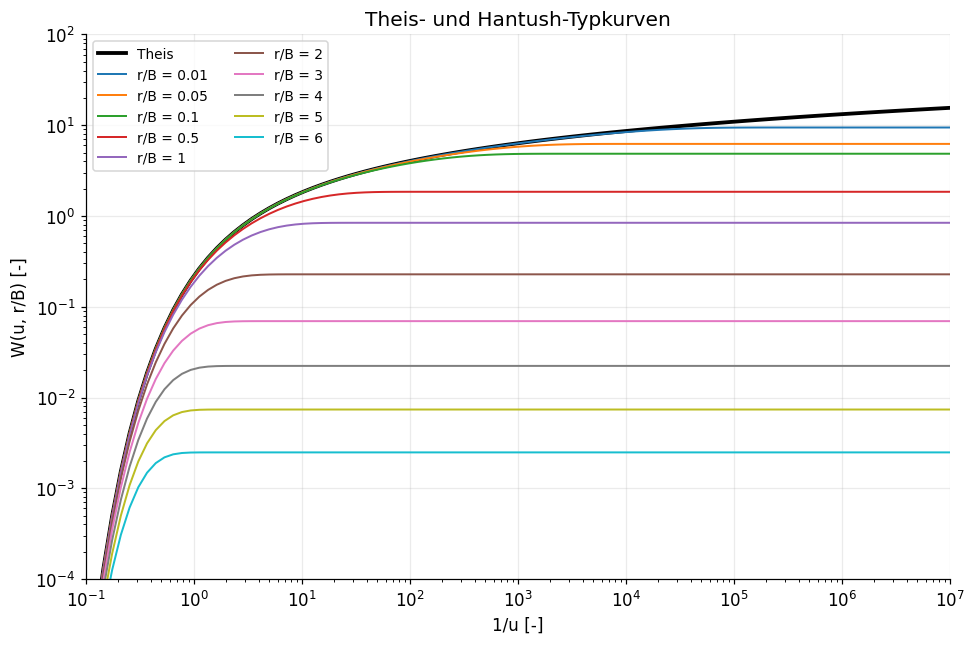

In [2]:
rho_type = np.array([0.01, 0.05, 0.1, 0.5, 1, 2, 3, 4, 5, 6], dtype=float)
u_type = np.logspace(-7, 1, 100)

fig, ax = plt.subplots(figsize=(9, 6))
ax.loglog(1/u_type, exp1(u_type), color="black", linewidth=2.5, label="Theis")
for rho in rho_type:
    w_h = np.array([hantush_well_function(float(u), float(rho)) for u in u_type])
    ax.loglog(1/u_type, w_h, linewidth=1.3, label=f"r/B = {rho:g}")
ax.set(xlabel="1/u [-]", ylabel="W(u, r/B) [-]", title=LABELS['type_title'],
       xlim=(1e-1, 1e7), ylim=(1e-4, 1e2))
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Synthetischer Pumpversuch

Wir erzeugen Messdaten mit bekannten Parametern und addieren ein geringes zufälliges Messrauschen. Der Zufallsgenerator erhält einen festen **Seed**, damit dieselben Messwerte bei jedem Durchlauf entstehen.

**Eingaben:** **Q = 0,002 m³/s**, **r = 10 m**, **T = 0,001 m²/s**, **S = 0,001**, **M′ = 3 m**, **K′ = 10⁻⁵ m/s**.

In [3]:
# Eingaben: simulierte Testdaten
Q_syn = 0.002                 # m³/s
r_syn = 10.0                 # m
T_syn, S_syn = 1e-3, 1e-3   # m²/s, -
M_prime, K_prime = 3.0, 1e-5  # m, m/s

t_syn = np.array([120, 160, 200, 300, 400, 500, 600, 700, 800,
                  900, 1000, 1200, 1400, 1600, 1800, 2000, 2400, 2800], dtype=float)

B_syn = calc_B(T_syn, M_prime, K_prime)
rho_syn = calc_rho(r_syn, B_syn)
s_syn_exact = hantush_drawdown(t_syn, T_syn, S_syn, Q_syn, r_syn, rho_syn)

rng = np.random.default_rng(42)
noise_relative = 0.005
s_syn = s_syn_exact * (1 + noise_relative * rng.standard_normal(len(t_syn)))

print(f"B = {B_syn:.3f} m; r/B = {rho_syn:.4f}")
print(f"n = {len(t_syn)}")

B = 17.321 m; r/B = 0.5774
n = 18


### 4.1 Zunächst: Messwerte mit linearen Achsen

Die Absenkung wird zunächst wie bei einer gewöhnlichen Messdatenkontrolle gegen die Zeit aufgetragen: **beide Achsen linear**.

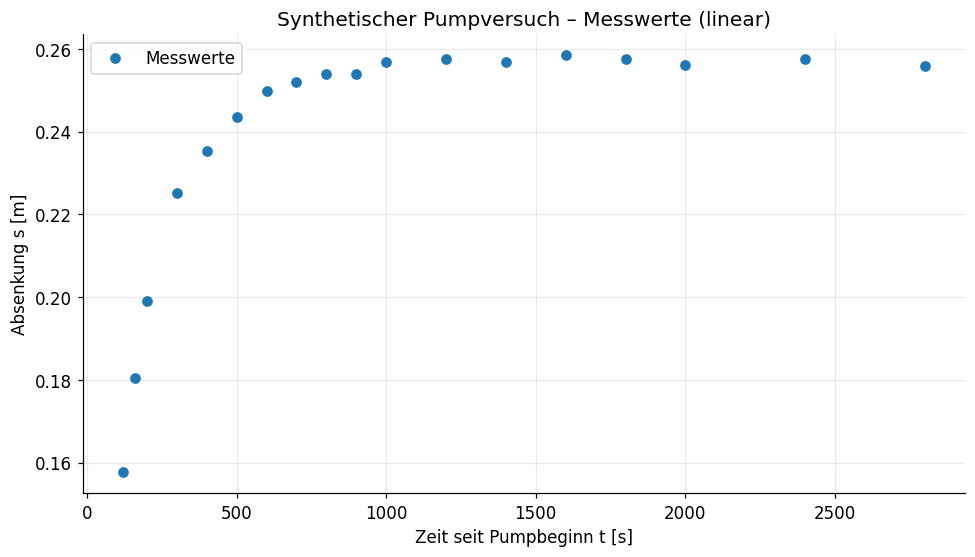

In [4]:
fig, ax = plt.subplots()
ax.plot(t_syn, s_syn, 'o', markersize=6, label=LABELS['obs'])
ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=LABELS['syn_observe'])
ax.legend()
fig.tight_layout()
plt.show()

### 4.2 Anpassung bei bekanntem **r/B**

Im ersten Schritt ist **r/B** aus den Eingabeparametern bekannt. Daher werden nur **T** und **S** mittels nichtlinearer kleinster Quadrate bestimmt. Das Diagramm mit Messwerten und Modellkurve ist **doppellogarithmisch**.

Wir verwenden einen realen **RMSE** (mittlere quadratische Abweichung unter der Wurzel), nicht die unnormierte Norm des Residuenvektors.

Bekanntes r/B = 0.5774
T = 1.0002e-03 m²/s
S = 1.0028e-03 [-]
RMSE = 0.00104 m


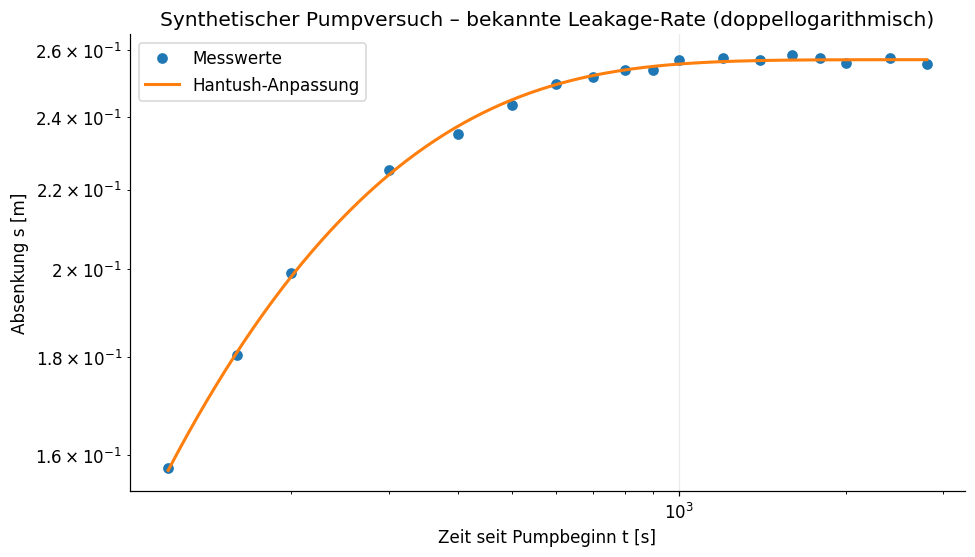

In [5]:
fit_known = fit_at_rho(t_syn, s_syn, Q_syn, r_syn, rho_syn)
print(LABELS['known'] + f" = {rho_syn:.4f}")
print(f"T = {fit_known['T']:.4e} m²/s")
print(f"S = {fit_known['S']:.4e} [-]")
print(f"RMSE = {fit_known['rmse']:.5f} m")
plot_fit(t_syn, s_syn, include_inputs(fit_known, Q_syn, r_syn), LABELS['syn_fit'])

### 4.3 Anpassung bei unbekanntem **r/B**

Bei einem realen Versuch kennen wir **r/B** in der Regel nicht. Wir testen daher mehrere **vorgegebene Werte von r/B**. Für jeden davon passen wir **T** und **S** separat an und vergleichen den RMSE.

**Wichtig:** Die Auswahl ist zunächst eine *diskrete Parametersuche*. Das Ergebnis ist der beste Wert **aus den getesteten Kandidaten**, nicht automatisch das exakte Optimum.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.010    5.2828e-03    2.5246e-05       0.01241
   0.050    3.6975e-03    1.3399e-04       0.00933
   0.100    2.9219e-03    2.7954e-04       0.00733
   0.500    1.1421e-03    9.5589e-04       0.00111
   1.000    5.2541e-04    1.0252e-03       0.00334
   2.000    1.4340e-04    6.1771e-04       0.00702
   3.000    4.3941e-05    2.9497e-04       0.00918
   4.000    1.4160e-05    1.2932e-04       0.01071
   5.000    4.6945e-06    5.4239e-05       0.01191
   6.000    1.5853e-06    2.2143e-05       0.01289

Beste Anpassung: r/B = 0.500, T = 1.1421e-03 m²/s, S = 9.5589e-04, RMSE = 0.00111 m


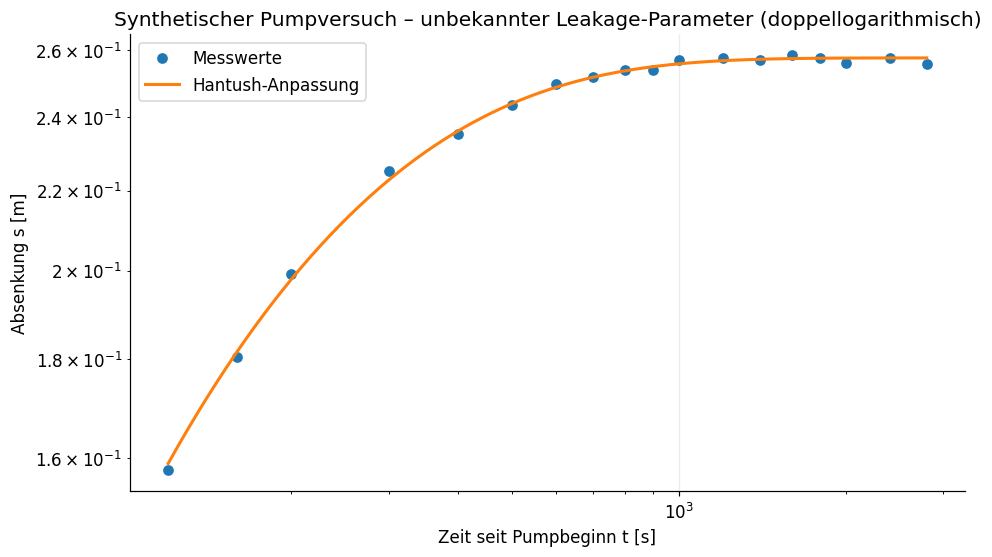

In [6]:
rho_coarse = np.array([0.01, 0.05, 0.1, 0.5, 1, 2, 3, 4, 5, 6])
fits_syn = scan_rho(t_syn, s_syn, Q_syn, r_syn, rho_coarse)
display_fit_table(fits_syn)
best_syn = fits_syn[0]
print("\n" + LABELS['summary_best'] + f": r/B = {best_syn['rho']:.3f}, "
      f"T = {best_syn['T']:.4e} m²/s, S = {best_syn['S']:.4e}, "
      f"RMSE = {best_syn['rmse']:.5f} m")
plot_fit(t_syn, s_syn, include_inputs(best_syn, Q_syn, r_syn), LABELS['syn_grid'])

**Interpretation:** Der getestete **r/B**-Wert sollte in der Nähe des bei der Simulation verwendeten Werts liegen. Ein Abweichen ist bei Rauschen und einer groben Kandidatenliste normal. Mehr Messdaten, eine feinere Suche oder mehrere Beobachtungsbrunnen können die Parameterschätzung verbessern.

## 5. Übungsaufgabe: Pumpversuch im halbgespannten Grundwasserleiter

Hier werden die **18 Messwerte** aus der Übungsaufgabe verwendet, mit **Q = 6 L/s = 0,006 m³/s** und **r = 40 m**. Die gemessenen Zeiten sind in **Sekunden**, die Absenkungen in **Metern** angegeben.

Zuerst werden die Messwerte **linear** dargestellt; anschließend wird **r/B** zunächst grob und dann feiner gesucht.

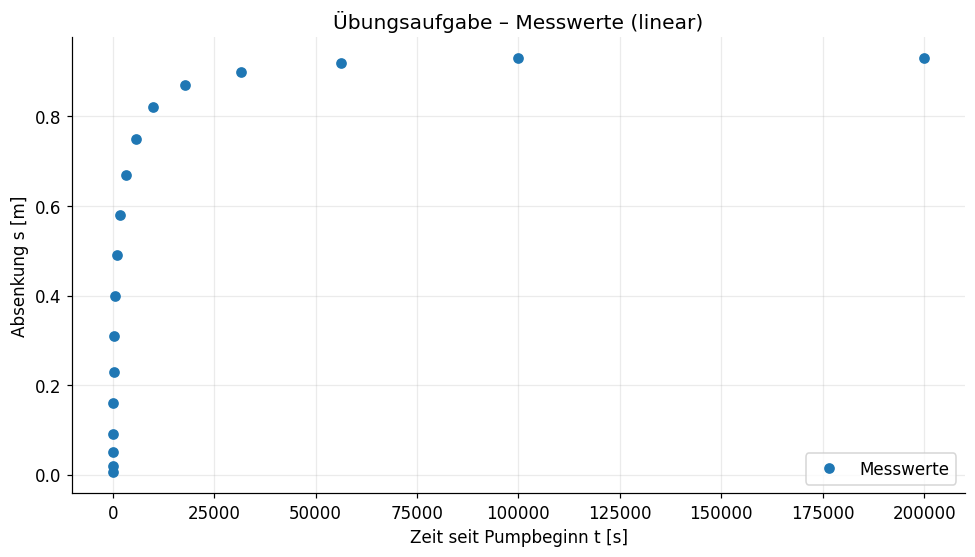

In [7]:
# Daten aus der Übungsaufgabe
Q_ex = 0.006
r_ex = 40.0

t_ex = np.array([10, 18, 32, 56, 100, 178, 316, 562, 1000,
                 1778, 3162, 5623, 10000, 17780, 31629, 56230, 100000, 200000], dtype=float)
s_ex = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31, 0.4, 0.49,
                 0.58, 0.67, 0.75, 0.82, 0.87, 0.9, 0.92, 0.93, 0.93], dtype=float)

assert len(t_ex) == len(s_ex) and np.all(np.diff(t_ex) > 0)

fig, ax = plt.subplots()
ax.plot(t_ex, s_ex, 'o', markersize=6, label=LABELS['obs'])
ax.set(xlabel=LABELS['time'], ylabel=LABELS['drawdown'], title=LABELS['real_observe'])
ax.legend()
fig.tight_layout()
plt.show()

### 5.1 Grobe Suche

Zuerst testen wir die oben verwendete Liste von **r/B**-Werten. Der Vergleich erfolgt anhand des **RMSE in Metern**. Die Anpassung an die Messwerte ist **doppellogarithmisch** dargestellt.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.010    4.0071e-03    1.0897e-04       0.05448
   0.050    3.1469e-03    1.7535e-04       0.01243
   0.100    2.5443e-03    2.4788e-04       0.01440
   0.500    1.0354e-03    4.2115e-04       0.07418
   1.000    4.8301e-04    3.7159e-04       0.09682
   2.000    1.3342e-04    1.9562e-04       0.11605
   3.000    4.1130e-05    8.8221e-05       0.12554
   4.000    1.3303e-05    3.7431e-05       0.13150
   5.000    4.4211e-06    1.5374e-05       0.13567
   6.000    1.4952e-06    6.1951e-06       0.13878

Beste Anpassung: r/B = 0.050, T = 3.1469e-03 m²/s, S = 1.7535e-04, RMSE = 0.01243 m


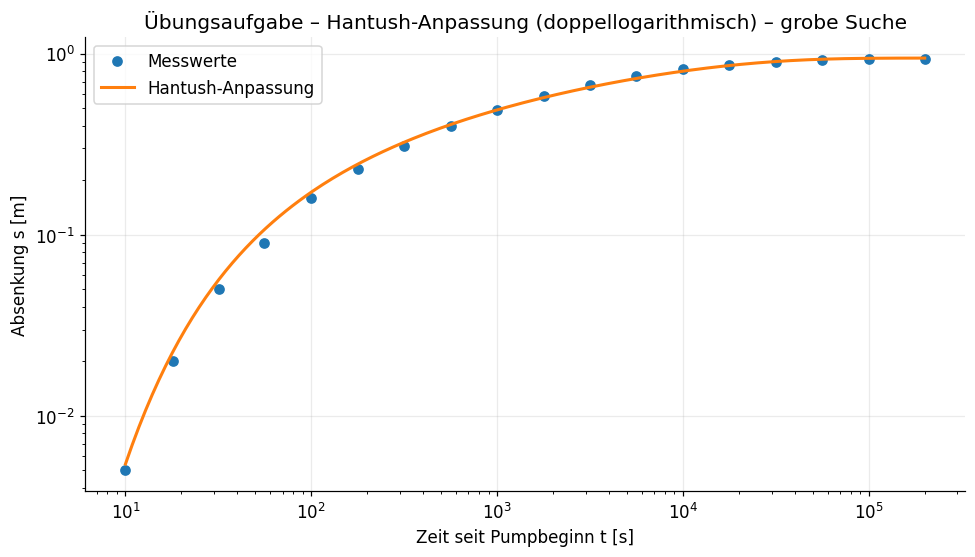

In [8]:
fits_ex_coarse = scan_rho(t_ex, s_ex, Q_ex, r_ex, rho_coarse)
display_fit_table(fits_ex_coarse)
best_ex_coarse = fits_ex_coarse[0]
print("\n" + LABELS['summary_best'] + f": r/B = {best_ex_coarse['rho']:.3f}, "
      f"T = {best_ex_coarse['T']:.4e} m²/s, S = {best_ex_coarse['S']:.4e}, "
      f"RMSE = {best_ex_coarse['rmse']:.5f} m")
plot_fit(t_ex, s_ex, include_inputs(best_ex_coarse, Q_ex, r_ex), LABELS['real_fit'] + (' – grobe Suche' if LANG == 'DE' else ' – coarse search'))

### 5.2 Verfeinerte Suche

Wir verfeinern das Suchraster für **r/B** nun weiter auf **0,04 bis 0,10** (Schrittweite 0,01). Durch dieses Vorgehen lässt sich der Einfluss der vorgegebenen Kandidaten anschaulich untersuchen.

Die Werte sind keine unabhängigen Beobachtungen der Leckage. **T**, **S** und **r/B** werden ausschließlich aus derselben Absenkungszeitreihe geschätzt; mögliche Parameterkorrelationen und Messfehler sind bei der Interpretation zu beachten.

     r/B      T [m²/s]         S [-]      RMSE [m]
-----------------------------------------------------
   0.040    3.3239e-03    1.5733e-04       0.02001
   0.050    3.1469e-03    1.7535e-04       0.01243
   0.060    2.9952e-03    1.9208e-04       0.00647
   0.070    2.8627e-03    2.0759e-04       0.00381
   0.080    2.7452e-03    2.2199e-04       0.00662
   0.090    2.6398e-03    2.3539e-04       0.01058
   0.100    2.5443e-03    2.4788e-04       0.01440

Beste Anpassung:
r/B = 0.070 [-]
T = 2.8627e-03 m²/s
S = 2.0759e-04 [-]
RMSE = 0.00381 m
B = 571.4 m
c = 1.1407e+08 s


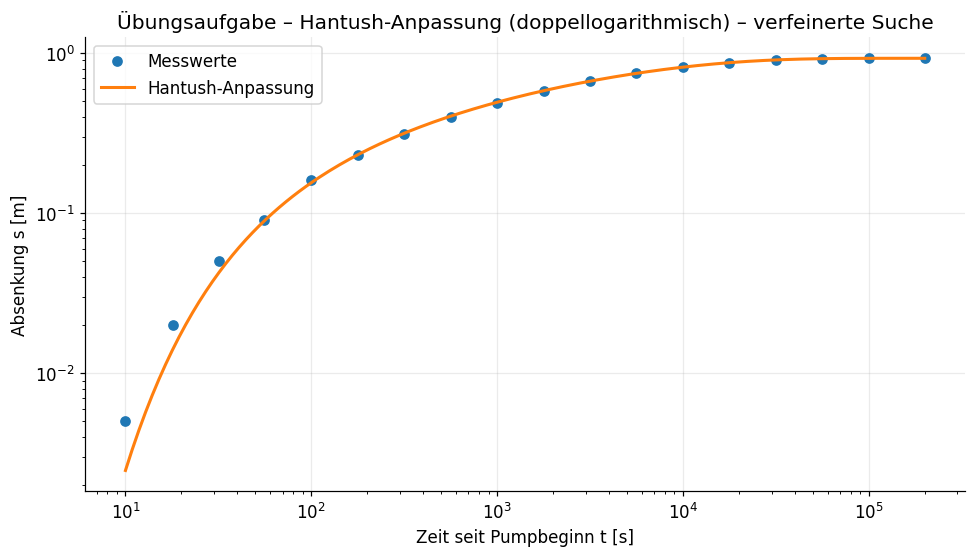

In [9]:
rho_fine = np.arange(0.04, 0.101, 0.01)
fits_ex_fine = scan_rho(t_ex, s_ex, Q_ex, r_ex, rho_fine)
display_fit_table(fits_ex_fine)
best_ex = fits_ex_fine[0]
B_ex = r_ex / best_ex['rho']
c_ex = B_ex**2 / best_ex['T']

print("\n" + LABELS['summary_best'] + ":")
print(f"r/B = {best_ex['rho']:.3f} [-]")
print(f"T = {best_ex['T']:.4e} m²/s")
print(f"S = {best_ex['S']:.4e} [-]")
print(f"RMSE = {best_ex['rmse']:.5f} m")
print(f"B = {B_ex:.1f} m")
print(f"c = {c_ex:.4e} s")
plot_fit(t_ex, s_ex, include_inputs(best_ex, Q_ex, r_ex), LABELS['real_fit'] + (' – verfeinerte Suche' if LANG == 'DE' else ' – refined search'))

### 5.3 Residuen und Interpretation

In einem zusätzlichen Diagramm werden die **Residuen (Messwert minus Modell)** linear dargestellt. Dadurch werden mögliche systematische Abweichungen leichter erkennbar. Trotz eines geringen RMSE garantiert eine gute Kurvenanpassung **keine eindeutige hydrogeologische Interpretation**.

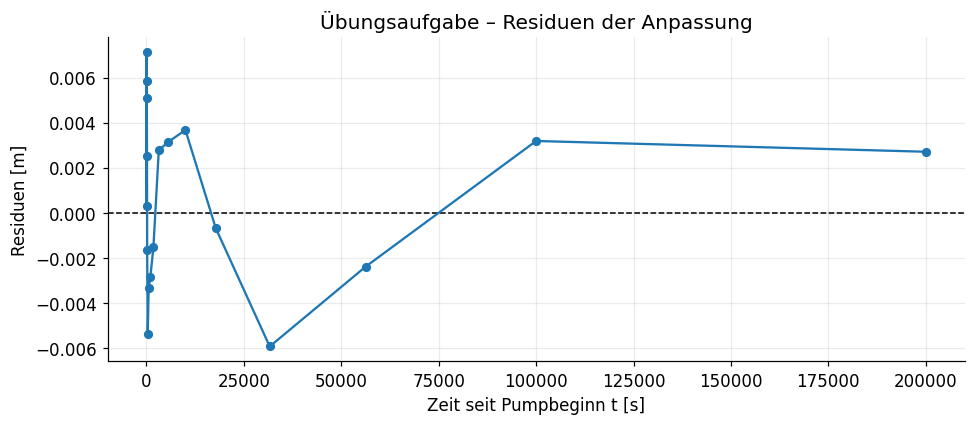

In [10]:
residuals_ex = s_ex - best_ex['prediction']
fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.plot(t_ex, residuals_ex, 'o-', markersize=5)
ax.set(xlabel=LABELS['time'], ylabel=LABELS['residuals'], title=LABELS['resid_title'])
fig.tight_layout()
plt.show()

### 5.4 Welche Parameter sind damit bestimmt?

Aus **r/B** folgt bei bekanntem **r** der Leakage-Faktor **B**. Mit der angepassten Transmissivität **T** lässt sich zudem der hydraulische Widerstand **c** berechnen:

$$
B=\frac{r}{r/B}, \qquad c=\frac{B^2}{T}, \qquad K'=\frac{M'}{c}.
$$

Ein Wert für **K′** ist **nur berechenbar, wenn die Mächtigkeit M′ zusätzlich bekannt ist**; diese ist in der Übungsaufgabe nicht angegeben. Aus dem Pumpversuch allein lassen sich **K′** und **M′** daher nicht getrennt ermitteln.

**Hinweis:** Die geschätzten Werte gelten im Rahmen der Modellannahmen. Spätere Abweichungen können u. a. auf Randbedingungen, zeitabhängige Leckage oder nicht berücksichtigte Speicherung in der Deckschicht hindeuten.

## 6. Zusammenfassung und Hinweise zur Anwendung

- **Theis** ist der Grenzfall ohne wirksame Leckage; **Hantush–Jacob** berücksichtigt vertikale Nachlieferung durch eine geringer durchlässige Schicht.
- Die **Typkurven** und **Hantush-Anpassungen** werden **doppellogarithmisch** dargestellt; die anfängliche Messdatenkontrolle erfolgt **linear**.
- Die hier demonstrierte Suche über **r/B** ist diskret. Weitere Kandidaten können das Ergebnis verändern; Unsicherheiten lassen sich aus dem RMSE allein nicht quantifizieren.
- Für eigene Daten **Q**, **r**, **t** und **s** in Abschnitt 5 ersetzen. Bei sehr kurzen Zeiten können Brunnenverluste und Brunnenspeicherung die Modellannahmen verletzen.

### Weiterführende Quellen

- Hantush, M. S. & Jacob, C. E. (1955): *Non-steady radial flow in an infinite leaky aquifer*. Transactions, American Geophysical Union, 36(1), 95–100. [DOI](https://doi.org/10.1029/TR036i001p00095).
- Olsthoorn, T. N.: [Well in a Leaky Aquifer – Transient Groundwater Flow](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html) (Code-Vorlage, online).
- [Grundwasser.net – Halbgespannter Aquifer (Hantush 1955)](https://www.grundwasser.net/pumpversuche/halbgespannter-aquifer-hantush) (Erläuterung zu Aquitarde, Leakage und Größenordnung der Durchlässigkeitsunterschiede).
- Langguth, H.-R. & Voigt, R. (1980): *Hydrogeologische Methoden*. Springer, Berlin, Heidelberg. [DOI](https://doi.org/10.1007/978-3-642-96581-4) (weiterführende Grundlagen; keine Belegquelle für exakte Grenzwerte).